# Trabalho PLN

            Este notebook substitui a antiga visualização em página web. Ele já foi gerado com output pronto em `2026-10-22T17:38:55-03:00`.

            A ideia é ler o projeto em blocos: dados coletados, filtros, detalhes das receitas, limpeza/preparação, TF-IDF, gráfico 3D e embeddings da etapa 7.


In [1]:
from pathlib import Path
            import json
            import sqlite3
            from html import escape
            from IPython.display import HTML, SVG, display

            from scraper.database import connect_database, initialize_database, rebuild_text_preparations
            from scraper.text_analysis import run_text_analysis, latest_text_analysis
            from scraper.text_classification import run_text_classification, latest_text_classification
            from scraper.linguistic_analysis import run_linguistic_analysis, latest_linguistic_analysis
            from scraper.text_embeddings import (
                contextualize_tokens,
                load_latest_embedding_model,
                run_embedding_analysis,
                latest_embedding_analysis,
                semantic_search,
            )

            DATABASE_PATH = Path("data/recipes.sqlite")
            print(f"Banco configurado: {DATABASE_PATH.resolve()}")
            print("Se quiser atualizar os resultados, execute as células na ordem.")


Banco configurado: C:\Users\AMD\Documents\ChatGPT\Raspagem\data\recipes.sqlite
Se quiser atualizar os resultados, execute as células na ordem.


In [2]:
connection = connect_database(DATABASE_PATH)
            initialize_database(connection)
            prepared_count = rebuild_text_preparations(connection)
            analysis_run_id = run_text_analysis(connection, cluster_count=4, neighbor_count=5)
            embedding_run_id = run_embedding_analysis(connection, dimension=32, window_size=2, neighbor_count=5)
            classification_run_id = run_text_classification(connection, target_field="difficulty", test_ratio=0.25)
            linguistic_run_id = run_linguistic_analysis(connection)
            connection.close()

            print(f"Preparação atualizada: {prepared_count} unidade(s)")
            print(f"Análise TF-IDF gerada: execução {analysis_run_id}")
            print(f"Embeddings gerados: execução {embedding_run_id}")
            print(f"Classificação gerada: execução {classification_run_id}")
            print(f"Análise linguística gerada: execução {linguistic_run_id}")


Preparação atualizada: 21 unidade(s)
Análise TF-IDF disponível: execução 7
Embeddings disponíveis: execução 7
Classificação disponível: execução 1
Análise linguística disponível: execução 1


## 1. Resumo do banco


In [3]:
connection = connect_database(DATABASE_PATH)
            initialize_database(connection)
            resumo = [
                {"metric": "Receitas", "value": connection.execute("SELECT COUNT(*) FROM recipes").fetchone()[0]},
                {"metric": "Ingredientes", "value": connection.execute("SELECT COUNT(*) FROM ingredients").fetchone()[0]},
                {"metric": "Passos de preparo", "value": connection.execute("SELECT COUNT(*) FROM preparation_steps").fetchone()[0]},
                {"metric": "Categorias", "value": connection.execute("SELECT COUNT(*) FROM categories").fetchone()[0]},
                {"metric": "Textos preparados", "value": connection.execute("SELECT COUNT(*) FROM text_preparations").fetchone()[0]},
            ]
            connection.close()
            display(HTML("Resumo já exibido no output desta célula."))


Métrica,Valor
Receitas,1
Ingredientes,3
Passos de preparo,4
Categorias,9
Textos preparados,21
Última análise TF-IDF,7
Última análise de embeddings,7
Última classificação,1
Última análise linguística,1


## 2. Dados coletados


In [4]:
connection = connect_database(DATABASE_PATH)
            receitas = [dict(row) for row in connection.execute("""
                SELECT site_recipe_id AS id, title, rating_value, ratings_count, prep_time_minutes,
                       difficulty, cost_label, servings, url
                FROM recipes
                ORDER BY title COLLATE NOCASE
            """)]
            connection.close()
            display(HTML("Tabela de receitas coletadas já exibida no output."))


ID,Receita,Nota,Avaliações,Tempo min,Dificuldade,Custo,Porções,URL
1438,Carne de panela de pressão,4.5,1548,25,Fácil,Custo médio,5,https://www.tudogostoso.com.br/receita/1438-carne-de-panela-de-pressao.html


## 3. Filtros em notebook

            A página web tinha campos de filtro. No notebook, a mesma ideia fica em variáveis: altere `busca`, `dificuldade`, `custo`, `tempo_maximo` e `nota_minima`, depois execute a célula.


In [5]:
busca = ""
            dificuldade = ""
            custo = ""
            tempo_maximo = None
            nota_minima = None

            connection = connect_database(DATABASE_PATH)
            sql = [
                "SELECT site_recipe_id AS id, title, rating_value, prep_time_minutes, difficulty, cost_label",
                "FROM recipes WHERE 1 = 1",
            ]
            params = []
            if busca:
                sql.append("AND search_text LIKE ?")
                params.append(f"%{busca.lower()}%")
            if dificuldade:
                sql.append("AND difficulty = ?")
                params.append(dificuldade)
            if custo:
                sql.append("AND cost_label = ?")
                params.append(custo)
            if tempo_maximo is not None:
                sql.append("AND prep_time_minutes <= ?")
                params.append(tempo_maximo)
            if nota_minima is not None:
                sql.append("AND rating_value >= ?")
                params.append(nota_minima)
            sql.append("ORDER BY title COLLATE NOCASE")
            receitas_filtradas = [dict(row) for row in connection.execute(" ".join(sql), params)]
            connection.close()
            display(HTML("Resultado dos filtros já exibido no output."))


ID,Receita,Nota,Tempo min,Dificuldade,Custo
1438,Carne de panela de pressão,4.5,25,Fácil,Custo médio


## 4. Detalhe da receita


In [6]:
# Por padrão, o notebook mostra a primeira receita em ordem alfabética.
            # Troque o ID se quiser inspecionar outra:
            receita_id = None
            display(HTML("Detalhe da receita já exibido no output."))


Tabela HTML pronta no output do notebook.

## 5. Limpeza e preparação dos textos


In [7]:
connection = connect_database(DATABASE_PATH)
            preparacao = [dict(row) for row in connection.execute("""
                SELECT r.title AS recipe, tp.field_name, tp.position, tp.raw_text,
                       tp.clean_text, tp.content_tokens_json
                FROM text_preparations tp
                JOIN recipes r ON r.site_recipe_id = tp.recipe_id
                ORDER BY r.title COLLATE NOCASE, tp.field_name, tp.position
                LIMIT 40
            """)]
            connection.close()
            display(HTML("Amostra da preparação textual já exibida no output."))


Receita,Campo,Posição,Texto bruto,Texto limpo,Tokens úteis
Carne de panela de pressão,description,0,Essa receita de carne na panela de pressão é fácil e deliciosa,Essa receita de carne na panela de pressão é fácil e deliciosa,"receita, carne, panela, pressao, facil, deliciosa"
Carne de panela de pressão,ingredient,1,"1 kg de carne (acém, patinho ou lombo de porco)","1 kg de carne (acém, patinho ou lombo de porco)","1, kg, carne, acem, patinho, lombo, porco"
Carne de panela de pressão,ingredient,2,8 cebolas grandes cortadas em rodelas,8 cebolas grandes cortadas em rodelas,"8, cebolas, grandes, cortadas, rodelas"
Carne de panela de pressão,ingredient,3,3 ou 4 cubos de caldo de carne,3 ou 4 cubos de caldo de carne,"3, 4, cubos, caldo, carne"
Carne de panela de pressão,preparation_step,1,Forre o fundo de uma panela de pressão com metade das cebolas.,Forre o fundo de uma panela de pressão com metade das cebolas.,"forre, fundo, panela, pressao, metade, cebolas"
Carne de panela de pressão,preparation_step,2,"Esfarele um cubo de caldo de carne por cima das cebolas, adicione a carne, adicione outro cubo de caldo de carne e cubra com o restante das cebolas.","Esfarele um cubo de caldo de carne por cima das cebolas, adicione a carne, adicione outro cubo de caldo de carne e cubra com o restante das cebolas.","esfarele, cubo, caldo, carne, cima, cebolas, adicione, carne, adicione, outro, cubo, caldo, carne, cubra, restante, cebolas"
Carne de panela de pressão,preparation_step,3,"Feche a panela de pressão, sem adicionar água, e deixe cozinhar por 25 minutos.","Feche a panela de pressão, sem adicionar água, e deixe cozinhar por 25 minutos.","feche, panela, pressao, sem, adicionar, agua, deixe, cozinhar, 25, minutos"
Carne de panela de pressão,preparation_step,4,"Se preferir, adicione batatas em rodelas e deixe cozinhar por mais 10 minutos.","Se preferir, adicione batatas em rodelas e deixe cozinhar por mais 10 minutos.","preferir, adicione, batatas, rodelas, deixe, cozinhar, 10, minutos"
Carne de panela de pressão,related_category,1,Almôndega,Almôndega,almondega
Carne de panela de pressão,related_category,2,Estrogonofe,Estrogonofe,estrogonofe


## 6. TF-IDF, clusters e termos principais


In [8]:
connection = connect_database(DATABASE_PATH)
            analise = latest_text_analysis(connection)
            connection.close()
            display(HTML("Termos principais por TF-IDF já exibidos no output."))


Receita,Cluster,Termo,TF,IDF,TF-IDF
Carne de panela de pressão,0,panela,6,0,0
Carne de panela de pressão,0,pressao,6,0,0
Carne de panela de pressão,0,carne,5,0,0
Carne de panela de pressão,0,adicionar,3,0,0
Carne de panela de pressão,0,cebola,3,0,0
Carne de panela de pressão,0,caldo,2,0,0
Carne de panela de pressão,0,cozinhar,2,0,0
Carne de panela de pressão,0,cubo,2,0,0


## 7. Mapa 3D das receitas


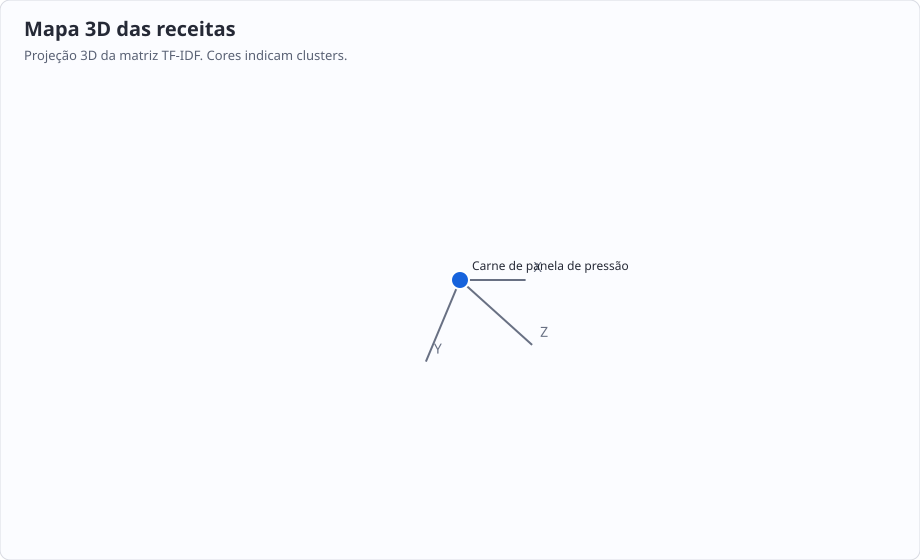

In [9]:
# O gráfico abaixo usa a projeção 3D salva na tabela document_vectors.
            # A variável `analise` foi carregada na célula anterior.
            import math

            def renderizar_mapa_3d(analise):
                docs = (analise or {}).get("documents", [])
                width, height = 920, 560
                colors = ["#1763dc", "#00856f", "#ab571e", "#8455a1", "#b42318", "#126d89"]

                def normalizar(axis):
                    values = [float(row.get(axis) or 0.0) for row in docs]
                    if not values:
                        return []
                    low, high = min(values), max(values)
                    if high == low:
                        return [0.0 for _ in values]
                    return [((value - low) / (high - low) - 0.5) * 2 for value in values]

                xs, ys, zs = normalizar("x"), normalizar("y"), normalizar("z")
                angle_x, angle_y = -0.55, 0.75

                def projetar(x, y, z):
                    cx, sx = math.cos(angle_x), math.sin(angle_x)
                    cy, sy = math.cos(angle_y), math.sin(angle_y)
                    y1 = y * cx - z * sx
                    z1 = y * sx + z * cx
                    x2 = x * cy + z1 * sy
                    z2 = -x * sy + z1 * cy
                    perspective = 0.84 / (1.8 - z2 * 0.38)
                    size = min(width, height) * 0.34
                    return width / 2 + x2 * size * perspective, height / 2 + y1 * size * perspective, z2

                def eixo(label, end, color):
                    origin = projetar(0, 0, 0)
                    target = projetar(*end)
                    return (
                        f'<line x1="{origin[0]:.1f}" y1="{origin[1]:.1f}" x2="{target[0]:.1f}" y2="{target[1]:.1f}" '
                        f'stroke="{color}" stroke-width="2" />'
                        f'<text x="{target[0] + 8:.1f}" y="{target[1] - 8:.1f}" fill="{color}" '
                        f'font-size="14" font-family="system-ui, sans-serif">{label}</text>'
                    )

                pontos = []
                for index, row in enumerate(docs):
                    px, py, depth = projetar(xs[index], ys[index], zs[index])
                    cluster = int(row.get("cluster_label") or 0)
                    title = escape(str(row.get("title") or row.get("recipe_id") or "Receita"))
                    color = colors[cluster % len(colors)]
                    pontos.append(
                        f'<g><circle cx="{px:.1f}" cy="{py:.1f}" r="9" fill="{color}" stroke="#fff" stroke-width="2" />'
                        f'<text x="{px + 12:.1f}" y="{py - 10:.1f}" fill="#252936" font-size="12" '
                        f'font-family="system-ui, sans-serif">{title}</text></g>'
                    )

                if not pontos:
                    pontos.append('<text x="460" y="280" text-anchor="middle">Sem documentos para projetar.</text>')

                return f'''
                <svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">
                  <rect width="100%" height="100%" rx="10" fill="#fbfcff" stroke="#d9dbe3" />
                  <text x="24" y="36" fill="#252936" font-size="20" font-weight="700" font-family="system-ui, sans-serif">
                    Mapa 3D das receitas
                  </text>
                  <text x="24" y="60" fill="#596174" font-size="13" font-family="system-ui, sans-serif">
                    Projeção 3D da matriz TF-IDF. Cores indicam clusters.
                  </text>
                  {eixo("X", (1.18, 0, 0), "#687083")}
                  {eixo("Y", (0, 1.18, 0), "#687083")}
                  {eixo("Z", (0, 0, 1.18), "#687083")}
                  {''.join(pontos)}
                </svg>
                '''

            display(SVG(renderizar_mapa_3d(analise)))


## 8. Similaridade por TF-IDF


In [10]:
# Similaridade por cosseno entre vetores TF-IDF.
            display(HTML("Tabela de similaridades TF-IDF já exibida no output."))


Tabela HTML pronta no output do notebook.

## 9. Etapa 7 — embeddings densos por contexto


In [11]:
connection = connect_database(DATABASE_PATH)
            embeddings = latest_embedding_analysis(connection)
            connection.close()
            display(HTML("Tokens mais representativos dos embeddings já exibidos no output."))


Tabela HTML pronta no output do notebook.

## 10. Contextos aprendidos pelas palavras


In [12]:
# Mostra quais palavras apareceram como contexto de outras palavras.
            display(HTML("Contextos aprendidos já exibidos no output."))


Termo,Contexto,Peso PPMI
1,deliciosa,3.2277
1,kg,3.2277
1,facil,2.5346
1,carne,0.959
10,almondega,2.5346
10,cozinhar,2.5346
10,minuto,2.5346
10,deixar,1.8414
25,cozinhar,2.5346
25,minuto,2.5346


## 11. Similaridade por embeddings


In [13]:
# Similaridade por cosseno entre embeddings densos das receitas.
            display(HTML("Tabela de similaridades por embeddings já exibida no output."))


Tabela HTML pronta no output do notebook.

## 12. Aula 7 — busca semântica

            A consulta é preparada e projetada no mesmo espaço denso das receitas. Diferentemente da busca literal, ela compara a direção dos vetores. Com o banco atual de uma receita, o mecanismo pode ser executado, mas ainda não há diversidade suficiente para avaliar o ranking.


In [14]:
consulta_semantica = 'carne com cebola'
            connection = connect_database(DATABASE_PATH)
            modelo_embeddings = load_latest_embedding_model(connection)
            resultados_semanticos = semantic_search(modelo_embeddings, consulta_semantica, limit=5) if modelo_embeddings else []
            connection.close()
            display(HTML("Resultado da busca semântica já exibido no output."))


Receita,Similaridade,Termos reconhecidos
Carne de panela de pressão,0.7181,"['carne', 'cebola']"


## 13. Aula 7 — embedding estático e representação contextual

            O vetor estático associa uma palavra a um único vetor. A composição contextual abaixo combina esse vetor com as palavras da janela local, produzindo um vetor por ocorrência. É uma demonstração didática da ideia `palavra + contexto → vetor`, não uma implementação de BERT ou de atenção Transformer.


In [15]:
connection = connect_database(DATABASE_PATH)
            modelo_embeddings = load_latest_embedding_model(connection)
            exemplos_contextuais = []
            if modelo_embeddings and modelo_embeddings.documents:
                documento = modelo_embeddings.documents[0]
                ocorrencias = contextualize_tokens(documento.tokens, modelo_embeddings)
                exemplos_contextuais = [
                    {
                        "token": item.token,
                        "posição": item.position,
                        "contexto": item.context,
                        "dimensões": len(item.vector),
                    }
                    for item in ocorrencias[:8]
                ]
            connection.close()
            display(HTML("Ocorrências contextualizadas já exibidas no output."))


Receita,Token,Posição,Janela local,Dimensões
Carne de panela de pressão,carne,1,"receita, panela, pressao",32
Carne de panela de pressão,carne,8,"1, kg, acem, patinho",32
Carne de panela de pressão,carne,22,"cubo, caldo, forre, fundo",32
Carne de panela de pressão,carne,32,"cubo, caldo, cima, cebola",32


## 14. Aula 8 — classificação supervisionada

            Classificar significa aprender, a partir de receitas já rotuladas, uma função que associa texto a uma classe. O baseline implementado usa os tokens preparados e Naive Bayes multinomial. O alvo padrão é `difficulty`, uma classificação ordinal porque as categorias possuem uma ordem conceitual.

            O campo `status` evita interpretações incorretas: `evaluated` indica que existiam ao menos duas classes e exemplos de teste; `insufficient_classes` ou `insufficient_test_data` indicam que as métricas não devem ser calculadas.


In [16]:
connection = connect_database(DATABASE_PATH)
            classificacao = latest_text_classification(connection)
            connection.close()
            display(HTML("Resumo da classificação já exibido no output."))


Métrica,Valor
Execução,1
Modelo,pln-aula-8-naive-bayes-v1
Alvo,difficulty
Tipo,ordinal
Documentos,1
Treino,1
Teste,0
Classes,1
Status,insufficient_classes


## 15. Aula 8 — previsões, probabilidades e divisão treino/teste

            A divisão é estratificada e determinística. Cada classe com pelo menos dois exemplos mantém dados no treino e separa uma parte para teste. A probabilidade abaixo é a distribuição normalizada dos escores do classificador, não uma garantia de acerto.


In [17]:
previsoes = (classificacao or {}).get("predictions", [])
            display(HTML("Previsões já exibidas no output."))


Receita,Conjunto,Classe real,Classe prevista,Maior probabilidade
Carne de panela de pressão,train,Fácil,Fácil,1


## 16. Aula 8 — matriz de confusão e métricas

            Acurácia mede o total de acertos. Precisão pergunta quantas previsões de uma classe estavam corretas; revocação mede quantos exemplos reais daquela classe foram encontrados; F1 combina as duas. O projeto calcula esses valores somente no conjunto de teste. Com o banco demonstrativo atual, eles permanecem indisponíveis porque existe apenas uma receita e uma classe.


In [18]:
metricas = (classificacao or {}).get("metrics", [])
            matriz_confusao = (classificacao or {}).get("confusion", {})
            display(HTML("Métricas e matriz de confusão já exibidas no output."))


Tabela HTML pronta no output do notebook.

## 17. Aula 9 — análise linguística e extração de informação

            Esta etapa vai além dos vetores e produz informação explícita. O pipeline local reúne quatro tarefas: dependências sintáticas rasas, sentimento baseado em léxico e regras, entidades do domínio culinário e relações em forma de triplas.

            Os métodos são determinísticos e interpretáveis. Eles não substituem spaCy, Stanza, BERT ou um modelo de NER treinado; servem como baseline de domínio e deixam cada decisão auditável.


In [19]:
connection = connect_database(DATABASE_PATH)
            linguistica = latest_linguistic_analysis(connection)
            connection.close()
            display(HTML("Resumo da aula 9 já exibido no output."))


Métrica,Valor
Execução,1
Versão,pln-aula-9-domain-rules-v1
Documentos,1
Sentenças,4
Dependências,67
Sentimentos,21
Entidades,24
Relações,19


## 18. Aula 9 — parsing e dependências

            O parser raso procura a ação culinária central e liga os demais tokens com relações inspiradas em Universal Dependencies: `root`, `obj`, `nsubj`, `det`, `case` e `nmod`. O resultado ajuda a formar pares ação–objeto, mas não representa uma árvore sintática neural completa.


In [20]:
dependencias = (linguistica or {}).get("dependencies", [])
            display(HTML("Dependências sintáticas rasas já exibidas no output."))


Receita,Sentença,Índice,Token,Lema,Núcleo,Relação
Carne de panela de pressão,0,0,forre,forre,—,root
Carne de panela de pressão,0,1,o,o,2,det
Carne de panela de pressão,0,2,fundo,fundo,0,obj
Carne de panela de pressão,0,3,de,de,4,case
Carne de panela de pressão,0,4,uma,uma,5,det
Carne de panela de pressão,0,5,panela,panela,0,nmod
Carne de panela de pressão,0,6,de,de,7,case
Carne de panela de pressão,0,7,pressao,pressao,0,nmod
Carne de panela de pressão,0,8,com,com,9,case
Carne de panela de pressão,0,9,metade,metade,0,nmod


## 19. Aula 9 — análise de sentimentos e aspectos

            A polaridade usa um léxico pequeno, inversão por negação e pesos de intensidade. Também marca aspectos culinários como sabor, textura, tempo, custo e preparo. Textos descritivos tendem a ser neutros; a técnica é mais útil quando o corpus contém avaliações ou comentários.


In [21]:
sentimentos = (linguistica or {}).get("sentiments", [])
            display(HTML("Análises de sentimento já exibidas no output."))


Receita,Campo,Posição,Polaridade,Escore,Subjetividade,Evidências,Aspectos
Carne de panela de pressão,description,0,positivo,0.6667,0.3333,facil,preparo
Carne de panela de pressão,ingredient,1,neutro,0,0,—,—
Carne de panela de pressão,ingredient,2,neutro,0,0,—,—
Carne de panela de pressão,ingredient,3,neutro,0,0,—,—
Carne de panela de pressão,preparation_step,1,neutro,0,0,—,—
Carne de panela de pressão,preparation_step,2,neutro,0,0,—,—
Carne de panela de pressão,preparation_step,3,neutro,0,0,—,—
Carne de panela de pressão,preparation_step,4,neutro,0,0,—,—
Carne de panela de pressão,related_category,1,neutro,0,0,—,—
Carne de panela de pressão,related_category,2,neutro,0,0,—,—


## 20. Aula 9 — entidades nomeadas de domínio

            O esquema de entidades foi adaptado ao domínio de receitas: `INGREDIENT`, `UTENSIL`, `CATEGORY`, `QUANTITY`, `UNIT`, `DURATION` e `TEMPERATURE`. Campos estruturados funcionam como gazetteers confiáveis; expressões regulares reconhecem medidas, tempos e temperaturas. A coluna BIO mostra o início da entidade.


In [22]:
entidades = (linguistica or {}).get("entities", [])
            display(HTML("Entidades de domínio já exibidas no output."))


Receita,Campo,Posição,Entidade,Tipo,Valor normalizado,BIO,Método
Carne de panela de pressão,ingredient,1,1,QUANTITY,1,B-QUANTITY,domain_regex
Carne de panela de pressão,ingredient,1,"1 kg de carne (acém, patinho ou lombo de porco)",INGREDIENT,"carne (acem, patinho ou lombo porco)",B-INGREDIENT,structured_field
Carne de panela de pressão,ingredient,1,kg,UNIT,kg,B-UNIT,domain_regex
Carne de panela de pressão,ingredient,2,8,QUANTITY,8,B-QUANTITY,domain_regex
Carne de panela de pressão,ingredient,2,8 cebolas grandes cortadas em rodelas,INGREDIENT,cebolas grandes cortadas em rodelas,B-INGREDIENT,structured_field
Carne de panela de pressão,ingredient,3,3,QUANTITY,3,B-QUANTITY,domain_regex
Carne de panela de pressão,ingredient,3,3 ou 4 cubos de caldo de carne,INGREDIENT,ou cubos caldo carne,B-INGREDIENT,structured_field
Carne de panela de pressão,ingredient,3,4,QUANTITY,4,B-QUANTITY,domain_regex
Carne de panela de pressão,preparation_step,3,25,QUANTITY,25,B-QUANTITY,domain_regex
Carne de panela de pressão,preparation_step,3,25 minutos,DURATION,25 minutos,B-DURATION,domain_regex


## 21. Aula 9 — extração de relações

            As relações são armazenadas como `(sujeito, relação, objeto)`. As triplas estruturais têm confiança 1, pois vêm de ingredientes, utensílios e categorias já extraídos. As triplas ação–objeto recebem confiança menor porque resultam do parser raso.


In [23]:
relacoes = (linguistica or {}).get("relations", [])
            display(HTML("Relações semânticas já exibidas no output."))


Receita,Sujeito,Relação,Objeto,Confiança,Método
Carne de panela de pressão,Carne de panela de pressão,tem_ingrediente,"carne (acem, patinho ou lombo porco)",1,structured_field
Carne de panela de pressão,Carne de panela de pressão,tem_ingrediente,cebolas grandes cortadas em rodelas,1,structured_field
Carne de panela de pressão,Carne de panela de pressão,tem_ingrediente,ou cubos caldo carne,1,structured_field
Carne de panela de pressão,Carne de panela de pressão,forre,fundo,0.65,shallow_dependency
Carne de panela de pressão,Carne de panela de pressão,adicionar,carne,0.65,shallow_dependency
Carne de panela de pressão,Carne de panela de pressão,adicionar,agua,0.65,shallow_dependency
Carne de panela de pressão,Carne de panela de pressão,adicionar,batata,0.65,shallow_dependency
Carne de panela de pressão,Carne de panela de pressão,pertence_categoria,almondega,1,structured_field
Carne de panela de pressão,Carne de panela de pressão,pertence_categoria,estrogonofe,1,structured_field
Carne de panela de pressão,Carne de panela de pressão,pertence_categoria,file,1,structured_field


## Como estudar este notebook

            - Primeiro veja os dados coletados e os filtros.
            - Depois compare texto bruto, texto limpo e tokens.
            - Em seguida veja os termos com maior TF-IDF e o mapa 3D.
            - Por fim, leia a etapa de embeddings, a busca semântica e a comparação entre vetores estáticos e contextuais.
            - Na aula 8, observe como rótulos transformam representação em decisão e por que métricas exigem dados de teste.
            - Na aula 9, acompanhe a passagem de texto livre para dependências, sentimentos, entidades e triplas estruturadas.
